In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error , root_mean_squared_error , mean_squared_error , r2_score   
from sklearn.linear_model import LinearRegression

In [2]:
df = pd.read_csv('dataset/house_price.csv')
df.head()

,area,rooms,price
0,2104,3,399900
1,1600,3,329900
2,2400,3,369000
3,1416,2,232000
4,3000,4,539900


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   area    47 non-null     int64
 1   rooms   47 non-null     int64
 2   price   47 non-null     int64
dtypes: int64(3)
memory usage: 1.2 KB


In [4]:
df.describe()

,area,rooms,price
count,47.000000,47.000000,47.000000
mean,2000.680851,3.170213,340412.659574
std,794.702354,0.760982,125039.899586
min,852.000000,1.000000,169900.000000
25%,1432.000000,3.000000,249900.000000
50%,1888.000000,3.000000,299900.000000
75%,2269.000000,4.000000,384450.000000
max,4478.000000,5.000000,699900.000000


Text(0, 0.5, 'Price in ₹ Crores')

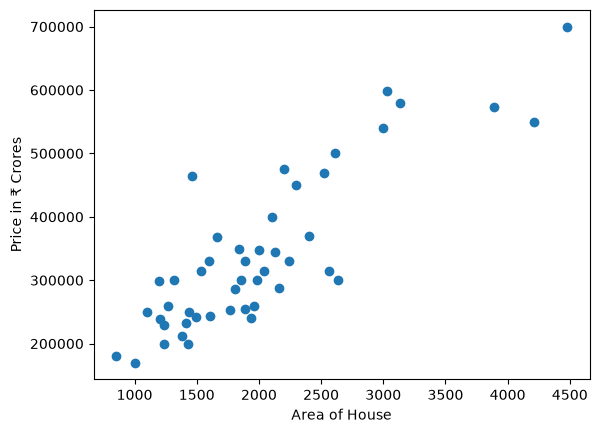

In [5]:
plt.scatter(df['area'] , df['price'])
plt.xlabel('Area of House')
plt.ylabel('Price in ₹ Crores')

In [6]:
df['area'].corr(df['price'])

np.float64(0.8549875928781253)

## The correlation coefficient between house area and price is approximately 0.85, indicating a strong positive linear relationship.

In [7]:
X = df.iloc[:,0:1]
y = df.iloc[:,-1]
y.head()

0    399900
1    329900
2    369000
3    232000
4    539900
Name: price, dtype: int64

In [8]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=13)
X_train.head()

,area
15,2300
14,1268
40,1664
44,852
20,1767


In [9]:
print(X_train.shape, y_train.shape)

(37, 1) (37,)


In [10]:
y_train = y_train.squeeze()
y_test = y_test.squeeze()

In [11]:
from sklearn.preprocessing import StandardScaler

# Fit on train only, so no test information leaks into the scaler
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model_s = LinearRegression().fit(X_train_s, y_train)
y_pred_s = model_s.predict(X_test_s)

model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[131.89]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['area']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8.112e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [12]:
print(model.coef_ , model.intercept_)

[131.88778324] 81121.38816303684


In [13]:
y_test.head()

6     314900
31    169900
4     539900
36    229900
39    287000
Name: price, dtype: int64

In [14]:
y_pred = model.predict(X_test)
y_pred[0:5]

array([283437.24765301, 213009.17140292, 476784.73788268, 244530.35159725,
       366262.77552766])

In [15]:
mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = root_mean_squared_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)


In [16]:
print(f"MAE : {mae}")
print(f"MSE : {mse}")
print(f"RMSE : {rmse}")
print(f"R2 : {r2}")

MAE : 61158.928362227176
MSE : 4576117793.4165745
RMSE : 67647.00875439042
R2 : 0.6239184229858483


In [17]:
mae = mean_absolute_error(y_test,y_pred_s)
mse = mean_squared_error(y_test,y_pred_s)
rmse = root_mean_squared_error(y_test,y_pred_s)
r2 = r2_score(y_test,y_pred_s)


In [18]:
print(f"MAE : {mae}")
print(f"MSE : {mse}")
print(f"RMSE : {rmse}")
print(f"R2 : {r2}")

MAE : 61158.928362227176
MSE : 4576117793.4165745
RMSE : 67647.00875439042
R2 : 0.6239184229858484


- On average model's predcition is misses the actual values by `61158.928` units(ruppes).
- The average squared error is `4576117793.416`, which heavyly penalised large prediction error.
- The typical deviation between prediction and actual data points is `67647` units.
- Input variable explains `62.39%` of the variance found in the target variable with respect to mean based prediction.

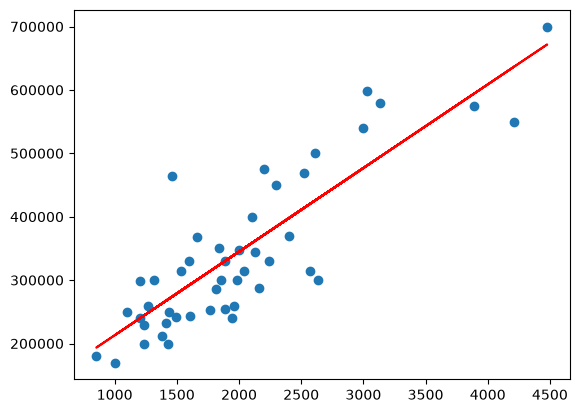

In [19]:
plt.scatter(X,y)
plt.plot(X,model.predict(X),color='red')

## Model coefficents 

In [20]:
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 131.88778323988086
Intercept: 81121.38816303684


In [21]:
comparison = pd.DataFrame({
    'Actual': y_test,
    'Prediction': y_pred
})

comparison['Error'] = comparison['Actual'] - comparison['Prediction']

print(comparison.head())

    Actual     Prediction         Error
6   314900  283437.247653  31462.752347
31  169900  213009.171403 -43109.171403
4   539900  476784.737883  63115.262117
36  229900  244530.351597 -14630.351597
39  287000  366262.775528 -79262.775528


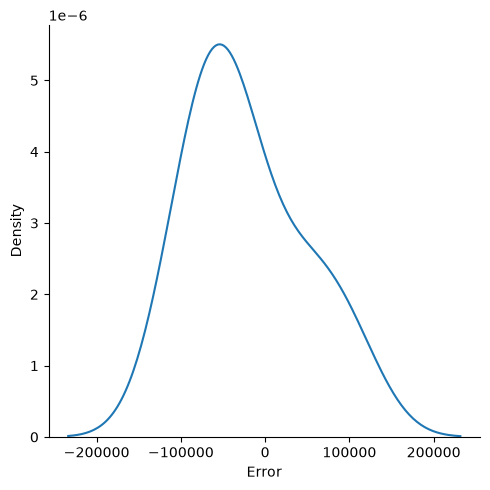

In [22]:
## The plot should be normally distrbuted as per assumption.
sns.displot(kind='kde',data=comparison,x='Error')


In [23]:
from sklearn.model_selection import cross_val_score

# Use full X and y (not X_train): cross-validation makes its own train/test splits
scores = cross_val_score(LinearRegression(), X, y, cv=5, scoring='r2')
print(scores)

print("Mean R2:", scores.mean(), "\n Std:", scores.std())

[0.78444411 0.79051448 0.48331746 0.72158262 0.36975947]
Mean R2: 0.6299236297104333 
 Std: 0.17160777041522748


## Summary :
- The model predicts house price from area using a straight line.
- Its slope means the predicted price increases by about 131.89 price units for each additional area unit.
- The intercept is the model’s prediction at zero area, which is outside the useful range for this dataset, so it has little practical meaning. 
- The model’s scores give a rough idea of its performance, but this dataset has only 47 houses, and some unusual observations may influence the fitted line. The model uses area alone, so it cannot account for other factors that affect house prices.